# 第098讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Experiment file present:', pathlib.Path('experiment.py').is_file())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Experiment file present: True


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "checks": {
    "lstm_cell_max_error": 0.0,
    "valid_loss": 1.2796443436030598,
    "padded_valid_loss": 1.2796443436030596,
    "loss_padding_error": 2.220446049250313e-16,
    "valid_readout_padding_error": 0.0,
    "wrong_last_readout_change": 0.022004750985094523,
    "constant_forget_0.9_after_50": 0.00515377520732012,
    "constant_forget_0.99_after_50": 0.6050060671375364
  },
  "configuration": {
    "train_examples": 192,
    "test_examples_per_length": 256,
    "hidden": 12,
    "updates": 200,
    "learning_rate": 0.02,
    "seeds": [
      0,
      1,
      2
    ],
    "train_length": 12,
    "data_seed": 198,
    "device": "cpu"
  },
  "evaluation": [
    {
      "seed": 0,
      "model": "RNN",
      "length": 12,
      "accuracy": 1.0,
      "loss": 8.47937844810076e-05,
      "parameters": 206
    },
    {
      "seed": 0,
      "model": "RNN",
      "length": 24,
      "accuracy": 1.0,
      "loss": 8.484127465635538e-05,
      "parameters": 206
    },
    {
   

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+'\n'.join(line for line in result.stderr.splitlines() if line.strip() != 'Fontconfig error: No writable cache directories'))

test_cell_reference (test_experiment.Tests.test_cell_reference) ... ok
test_empty_mask (test_experiment.Tests.test_empty_mask) ... ok
test_finite_gradient (test_experiment.Tests.test_finite_gradient) ... ok
test_masked_loss_padding (test_experiment.Tests.test_masked_loss_padding) ... ok
test_reproducibility (test_experiment.Tests.test_reproducibility) ... ok
test_valid_state_padding (test_experiment.Tests.test_valid_state_padding) ... ok
test_wrong_last_state_counterexample (test_experiment.Tests.test_wrong_last_state_counterexample) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.075s

OK


In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['checks', 'configuration', 'evaluation', 'scope']


01_results.png
02_mechanism.png


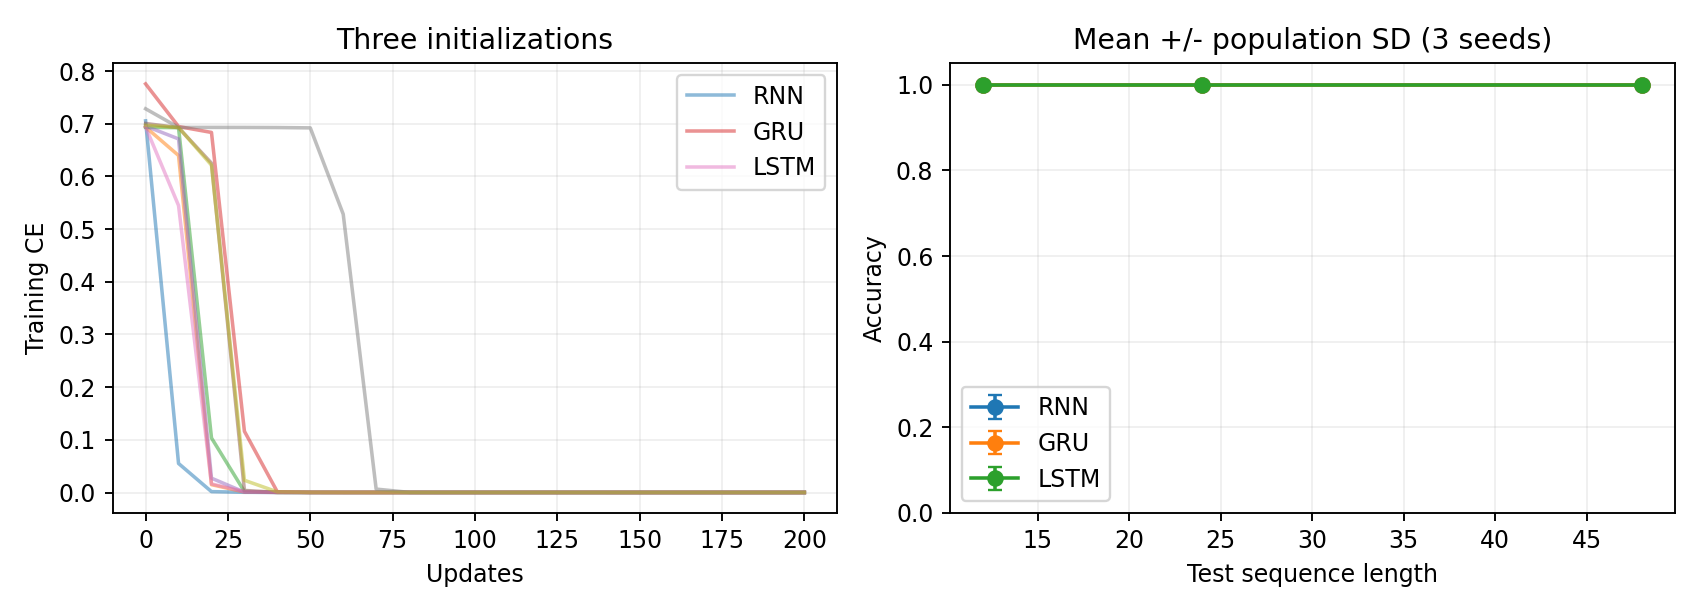

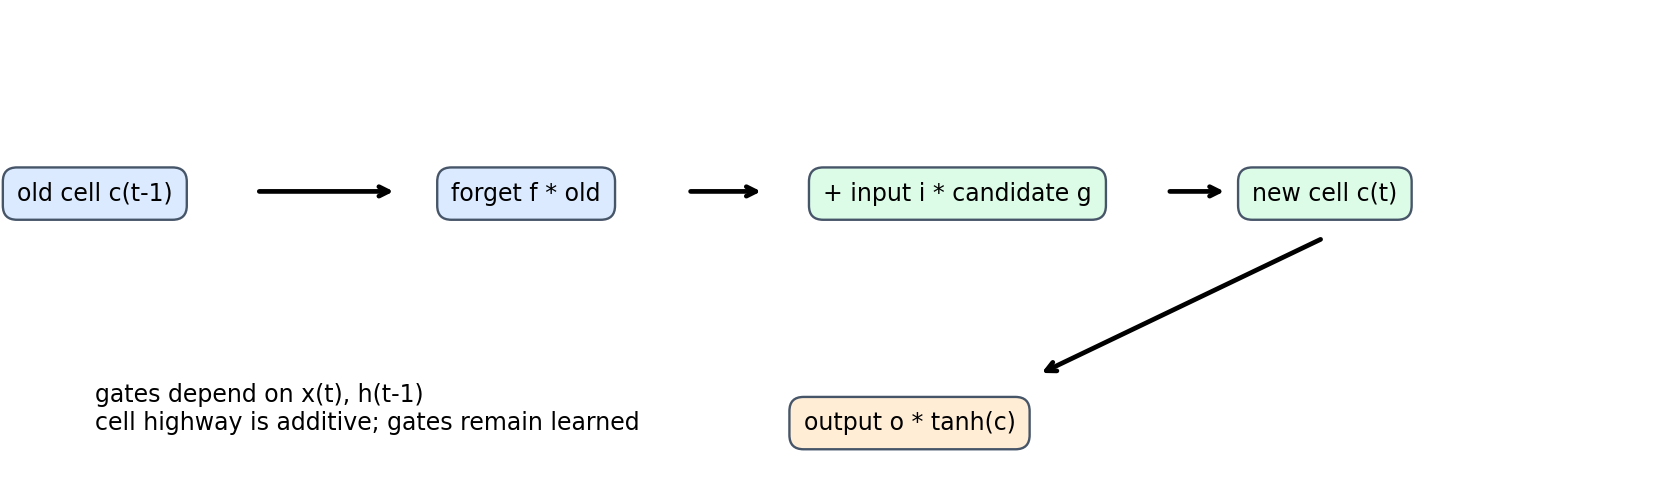

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。